# Fig. 8b: vacancy migration barriers

This notebook reproduces Fig. 8b of the DefectNet paper from scratch: climbing-image nudged elastic band (CI-NEB)
paths of the nearest-neighbour hop of V$_{Cd}^{2-}$ in CdSe$_{0.06}$Te$_{0.94}$, V$_{Ag}^{-}$ in Ag$_2$CdGeS$_4$ and
V$_{Cu}^{-}$ in CuGaSeTe (both in ordering II), starting from the DFT geometries of the pristine cells. It takes about
15 minutes on one GPU.

Open this notebook from the `examples/paper/` folder of the repository. The DFT data it needs are in `data/` as
Apache Arrow tables (see `README.md` in this folder for the columns), and the model is the `DefectNet-v1.0.pt` weights file
of the v1.0 release. A GPU is strongly recommended.

## Install and download the model

The cell below installs TACE at commit `057e463` with the patch in `patches/`, the DefectNet package and `pyarrow`,
skipping every step that is already done. Install PyTorch for your machine first (pytorch.org). The weights
(`DefectNet-v1.0.pt`, 891 MB) are downloaded with the GitHub command-line tool unless a copy is already here or in
`examples/`.

In [1]:
%%bash
cd ../..                                         # repository root
if python -c "import tace" 2>/dev/null; then echo "TACE is already installed"
else
  git clone -q https://github.com/xvzemin/tace.git ../tace
  git -C ../tace checkout -q 057e463
  git -C ../tace apply "$PWD/patches/tace-057e463.patch"
  pip install -q -e ../tace
fi
python -c "import defectnet" 2>/dev/null && echo "DefectNet is already installed" || pip install -q -e .
python -c "import pyarrow" 2>/dev/null && echo "pyarrow is already installed" || pip install -q pyarrow
cd examples/paper
if [ -f DefectNet-v1.0.pt ]; then echo "DefectNet-v1.0.pt is already here"
elif [ -f ../DefectNet-v1.0.pt ]; then ln -s ../DefectNet-v1.0.pt . && echo "using ../DefectNet-v1.0.pt"
else gh release download v1.0 -R msehabibur/DefectNet -p DefectNet-v1.0.pt; fi

TACE is already installed


DefectNet is already installed


pyarrow is already installed


DefectNet-v1.0.pt is already here


## Load the model and the data

Every row of an Arrow table is one DFT calculation. `atoms(row)` builds the ASE structure the benchmark started from
(the DFT input geometry of a defect cell, the DFT final geometry of a pristine cell), and `seed(row)` is the random
seed of its rattle, the CRC32 checksum of the row's `path`, so a relaxation here starts from exactly the same
displaced atoms as in the paper. GPU arithmetic is not bit-for-bit reproducible across devices, so energies can
differ from the paper values by a few meV.

In [2]:
import logging
import warnings
warnings.filterwarnings("ignore")
logging.disable(logging.WARNING)                 # hides TACE's start-up notes

import zlib
import numpy as np
import matplotlib.pyplot as plt
import pyarrow.feather as feather
from ase import Atoms

import defectnet as dn


def table(name):
    return feather.read_table(f"data/{name}.arrow").to_pylist()


def atoms(row, positions="start_positions"):
    return Atoms(row["start_symbols"], positions=row[positions], cell=row["start_cell"], pbc=True)


def seed(row):
    return zlib.crc32(row["path"].encode())


calc = dn.load("DefectNet-v1.0.pt", functional="PBEsol")
pristine = {r["path"]: r for r in table("pristine_pbesol")}
print(len(pristine), "pristine cells, PBEsol")

15 pristine cells, PBEsol


## Pristine cells and hop sites

Each pristine cell is relaxed as in the benchmark (rattled DFT geometry, FIRE to 0.02 eV/Å, cell fixed). The
vacancy is put on site $i$ and the hopping atom is its nearest neighbour $j$ of the same species. In the alloy
CdSe$_{0.06}$Te$_{0.94}$, $i$ is the Cd with the fewest Se neighbours within 3.2 Å; otherwise it is the first atom of the
species.

In [3]:
CASES = {"V_Cd": ("DFT/pristine/PBEsol__CdSe0.06Te0.94__216at__None", "Cd", -2, 1.02, 4.57),
         "V_Ag": ("DFT/pristine/PBEsol__Ag2Cd1Ge1S4_stannite__288at__1x1x1", "Ag", -1, 0.69, 3.94),
         "V_Cu": ("DFT/pristine/PBEsol__Cu1Ga1Se1Te1_stannite__288at__1x1x1", "Cu", -1, 1.16, 4.06)}

hosts = {}
for name, (path, el, q, _, _) in CASES.items():
    P = dn.relax(atoms(pristine[path]), calc, q=0, seed=seed(pristine[path]))
    sym = np.array(P.get_chemical_symbols())
    D = P.get_all_distances(mic=True)
    same = np.nonzero(sym == el)[0]
    anion = [k for k in range(len(P)) if sym[k] in ("Se", "S")]
    i = min(same, key=lambda k: (sum(D[k, x] < 3.2 for x in anion) if el == "Cd" else 0, k))
    j = min((k for k in same if k != i), key=lambda k: D[i, k])
    hosts[name] = (P, int(i), int(j))
    print(f"{name}: {pristine[path]['host']}, {len(P)} atoms, vacancy site {i}, hopping atom {j}, hop {D[i, j]:.2f} A")

V_Cd: CdSe0.06Te0.94, 216 atoms, vacancy site 8, hopping atom 107, hop 4.57 A


V_Ag: Ag2Cd1Ge1S4_stannite, 288 atoms, vacancy site 36, hopping atom 68, hop 3.94 A


V_Cu: Cu1Ga1Se1Te1_stannite, 288 atoms, vacancy site 0, hopping atom 20, hop 4.06 A


## CI-NEB

`dn.vacancy_hop` relaxes the initial state (atom $i$ removed) and the final state (atom $j$ moved onto site $i$)
with LBFGS to 0.01 eV/Å, interpolates seven images with IDPP, relaxes the band with FIRE to 0.1 eV/Å and then with a
climbing image to 0.03 eV/Å. The migration barrier is the highest image energy above the initial state,

$$E_m = \max_k E_k - E_0 ,$$

and the reaction coordinate is the cumulative distance between consecutive images, $s_k = \sum_{l<k} |\mathbf R_{l+1} - \mathbf R_l|$.

V_Cd: hop 4.57 A, barrier 1.02 eV forward, 1.02 eV backward, converged True   (paper: 1.02 eV, hop 4.57 A)


V_Ag: hop 3.94 A, barrier 0.68 eV forward, 0.68 eV backward, converged True   (paper: 0.69 eV, hop 3.94 A)


V_Cu: hop 4.06 A, barrier 1.16 eV forward, 1.16 eV backward, converged True   (paper: 1.16 eV, hop 4.06 A)


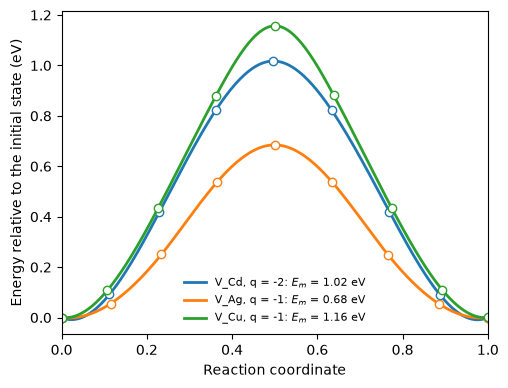

In [4]:
from scipy.interpolate import CubicSpline


def mic(a, d):
    f = np.linalg.solve(a.cell.T, np.atleast_2d(d).T).T
    return (f - np.round(f)) @ a.cell.array


fig, ax = plt.subplots(figsize=(5.5, 4.2))
for (name, (path, el, q, Em_paper, hop_paper)), col in zip(CASES.items(), ["#1f77b4", "#ff7f0e", "#2ca02c"]):
    P, i, j = hosts[name]
    r = dn.vacancy_hop(P, site=i, calc=calc, q=q, neighbour=j)
    im = r["images"]
    s = np.cumsum([0.0] + [np.linalg.norm(mic(a, b.positions - a.positions)) for a, b in zip(im[:-1], im[1:])])
    s, e = s / s[-1], np.array(r["E"]) - r["E"][0]
    xs = np.linspace(0, 1, 300)
    ax.plot(xs, CubicSpline(s, e)(xs), color=col, lw=2, label=f"{name}, q = {q:+d}: $E_m$ = {r['Em_fwd']:.2f} eV")
    ax.plot(s, e, "o", mfc="white", mec=col)
    print(f"{name}: hop {r['hop_length']:.2f} A, barrier {r['Em_fwd']:.2f} eV forward, {r['Em_bwd']:.2f} eV backward, "
          f"converged {r['converged']}   (paper: {Em_paper:.2f} eV, hop {hop_paper:.2f} A)")
ax.set_xlim(0, 1)
ax.set_xlabel("Reaction coordinate")
ax.set_ylabel("Energy relative to the initial state (eV)")
ax.legend(frameon=False, fontsize=8)
plt.show()